In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os

print("Diretório existe:", os.path.exists("/kaggle/input"))
print("Conteúdo:", os.listdir("/kaggle/input"))

for dirname, _, filenames in os.walk('/kaggle/input'):
    print("Pasta:", dirname)
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub


Diretório existe: True
Conteúdo: ['datasets']
Pasta: /kaggle/input
Pasta: /kaggle/input/datasets
Pasta: /kaggle/input/datasets/kelvynandrade
Pasta: /kaggle/input/datasets/kelvynandrade/dados-para-treinamento
/kaggle/input/datasets/kelvynandrade/dados-para-treinamento/test.csv
/kaggle/input/datasets/kelvynandrade/dados-para-treinamento/train.jsonl
/kaggle/input/datasets/kelvynandrade/dados-para-treinamento/validation.jsonl


In [3]:
import json

BASE_PATH = "/kaggle/input/datasets/kelvynandrade/dados-para-treinamento"

def load_jsonl(path):
    data = []

    with open(path, "r", encoding="utf-8") as file:
        for line in file:
            if line.strip():
                data.append(json.loads(line))

    return pd.DataFrame(data)

train = load_jsonl(f"{BASE_PATH}/train.jsonl")
validation = load_jsonl(f"{BASE_PATH}/validation.jsonl")
test = pd.read_csv(f"{BASE_PATH}/test.csv")

In [4]:
print("Dimensões dos datasets:")
print(f"Train:      {train.shape}")
print(f"Validation: {validation.shape}")
print(f"Test:       {test.shape}")

print("\nColunas:")
print("Train:", train.columns.tolist())
print("Validation:", validation.columns.tolist())
print("Test:", test.columns.tolist())

Dimensões dos datasets:
Train:      (3990, 5)
Validation: (570, 5)
Test:       (1140, 2)

Colunas:
Train: ['id', 'text', 'label', 'tokens', 'labels']
Validation: ['id', 'text', 'label', 'tokens', 'labels']
Test: ['id', 'text']


In [5]:
datasets = {
    "Train": train,
    "Validation": validation,
    "Test": test
}

for name, df in datasets.items():
    print(f"\n{'='*45}")
    print(name)
    print(f"{'='*45}")

    print("\nValores ausentes:")
    print(df.isnull().sum())

    print("\nDuplicações:")
    print("IDs duplicados:", df["id"].duplicated().sum())
    print("Textos duplicados:", df["text"].duplicated().sum())

    print("\nIDs únicos:", df["id"].nunique())
    print("Textos únicos:", df["text"].nunique())


Train

Valores ausentes:
id        0
text      0
label     0
tokens    0
labels    0
dtype: int64

Duplicações:
IDs duplicados: 0
Textos duplicados: 6

IDs únicos: 3990
Textos únicos: 3984

Validation

Valores ausentes:
id        0
text      0
label     0
tokens    0
labels    0
dtype: int64

Duplicações:
IDs duplicados: 0
Textos duplicados: 0

IDs únicos: 570
Textos únicos: 570

Test

Valores ausentes:
id      0
text    0
dtype: int64

Duplicações:
IDs duplicados: 0
Textos duplicados: 1

IDs únicos: 1140
Textos únicos: 1139


In [6]:
train_texts = set(train["text"])
validation_texts = set(validation["text"])
test_texts = set(test["text"])

print("Train x Validation:",
      len(train_texts & validation_texts))

print("Train x Test:",
      len(train_texts & test_texts))

print("Validation x Test:",
      len(validation_texts & test_texts))

Train x Validation: 1
Train x Test: 1
Validation x Test: 0


In [7]:
# Duplicações dentro do treinamento
duplicates = train[
    train["text"].duplicated(keep=False)
].sort_values("text")

display(duplicates[["id", "text", "label"]])

,id,text,label
526,4.287.H,O que diz um ouriço quando entra na casa de ba...,1
1357,4.364.H,O que diz um ouriço quando entra na casa de ba...,1
57,5.1838.N,O que o velho vaidoso disse em frente ao espel...,0
3566,5.2548.N,O que o velho vaidoso disse em frente ao espel...,0
1371,5.2613.N,Por que ninguém suportava o caipira que pilota...,0
1762,5.1903.N,Por que ninguém suportava o caipira que pilota...,0
539,5.1829.N,Por que o oficial pediu licença bem no dia do ...,0
808,5.2539.N,Por que o oficial pediu licença bem no dia do ...,0
391,5.1847.N,Qual é o jogador brasileiro que não chega a ca...,0
2823,5.2557.N,Qual é o jogador brasileiro que não chega a ca...,0


In [8]:
duplicate_analysis = (
    train.groupby("text")
    .agg(
        occurrences=("id", "count"),
        different_labels=("label", "nunique"),
        labels=("label", list),
        ids=("id", list)
    )
    .query("occurrences > 1")
)

display(duplicate_analysis)

,occurrences,different_labels,labels,ids
text,,,,
O que diz um ouriço quando entra na casa de banho? Cacheiro!,2,1,"[1, 1]","[4.287.H, 4.364.H]"
O que o velho vaidoso disse em frente ao espelho? Lindo!,2,1,"[0, 0]","[5.1838.N, 5.2548.N]"
Por que ninguém suportava o caipira que pilotava um caça? Porque era um chato de galocha.,2,1,"[0, 0]","[5.2613.N, 5.1903.N]"
Por que o oficial pediu licença bem no dia do bombardeio? Porque ele tinha medo.,2,1,"[0, 0]","[5.1829.N, 5.2539.N]"
Qual é o jogador brasileiro que não chega a caprichar na pontaria? Fred.,2,1,"[0, 0]","[5.1847.N, 5.2557.N]"
Um cara entrou na Ralph Lauren e deitou no chão . Qual o nome do filme? Detona Ralph.,2,1,"[0, 0]","[5.1880.N, 5.2590.N]"


In [9]:
overlap_train_val = train[
    train["text"].isin(validation["text"])
][["id", "text", "label"]]

overlap_train_test = train[
    train["text"].isin(test["text"])
][["id", "text", "label"]]

print("Train x Validation")
display(overlap_train_val)

print("Train x Test")
display(overlap_train_test)

Train x Validation


,id,text,label
925,4.295.H,Os termómetros foram festejar o início do verã...,1


Train x Test


,id,text,label
113,5.1910.N,Em qual cidade ninguém é mais virgem? Juiz de ...,0


In [10]:
for name, df in [
    ("Train", train),
    ("Validation", validation)
]:
    print(f"\n{name}")

    distribution = pd.DataFrame({
        "Quantidade": df["label"].value_counts().sort_index(),
        "Percentual": (
            df["label"].value_counts(normalize=True).sort_index() * 100
        ).round(2)
    })

    display(distribution)


Train


,Quantidade,Percentual
label,,
0,1995,50.0
1,1995,50.0



Validation


,Quantidade,Percentual
label,,
0,285,50.0
1,285,50.0


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, df) in zip(
    axes,
    [("Treinamento", train), ("Validação", validation)]
):
    sns.countplot(
        data=df,
        x="label",
        hue="label",
        legend=False,
        ax=ax
    )

    ax.set_title(f"Distribuição das classes - {name}")
    ax.set_xlabel("Classe")
    ax.set_ylabel("Quantidade")

plt.tight_layout()
plt.show()

In [11]:
# Criar atributos auxiliares
for df in [train, validation, test]:
    df["char_count"] = df["text"].str.len()
    df["word_count"] = df["text"].str.split().str.len()

# Estatísticas por classe
display(
    train.groupby("label")[["char_count", "word_count"]]
    .agg(["mean", "median", "std", "min", "max"])
    .round(2)
)

char_count                        word_count                     
            mean median    std min  max       mean median   std min max
label                                                                  
0          65.65   61.0  21.44  25  222      12.19   11.0  4.28   5  41
1          67.33   63.0  20.97  23  231      12.29   12.0  4.05   3  42

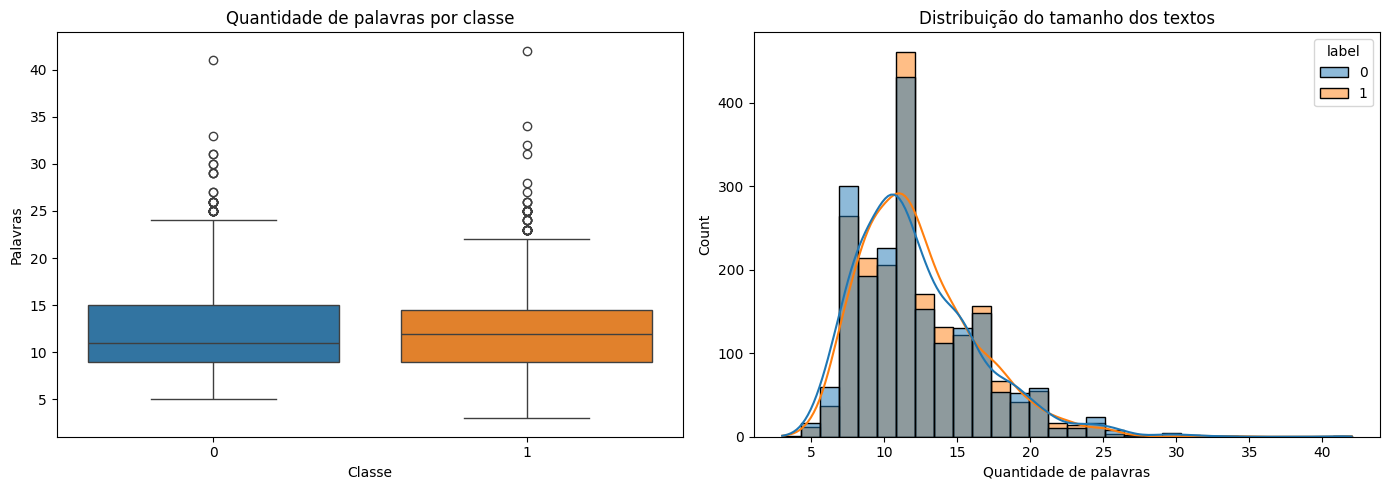

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=train,
    x="label",
    y="word_count",
    hue="label",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Quantidade de palavras por classe")
axes[0].set_xlabel("Classe")
axes[0].set_ylabel("Palavras")

sns.histplot(
    data=train,
    x="word_count",
    hue="label",
    bins=30,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Distribuição do tamanho dos textos")
axes[1].set_xlabel("Quantidade de palavras")

plt.tight_layout()
plt.show()

In [13]:
def count_marked_tokens(labels):
    return sum(value == 1 for value in labels)

train["marked_tokens"] = train["labels"].apply(count_marked_tokens)

display(
    train.groupby("label")["marked_tokens"]
    .describe()
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,1995.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0
1,1995.0,1.62,1.0,1.0,1.0,1.0,2.0,12.0


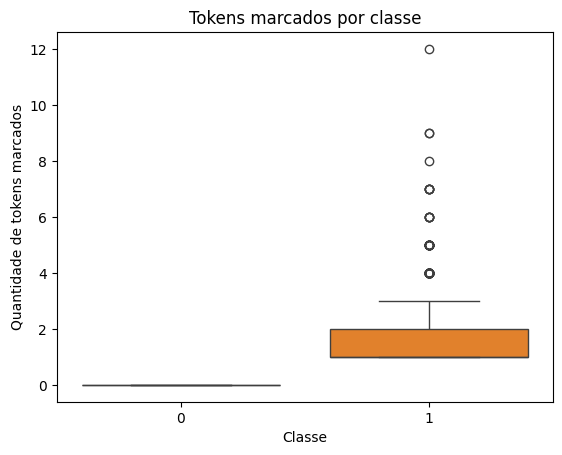

In [14]:
sns.boxplot(
    data=train,
    x="label",
    y="marked_tokens",
    hue="label",
    legend=False
)

plt.title("Tokens marcados por classe")
plt.xlabel("Classe")
plt.ylabel("Quantidade de tokens marcados")
plt.show()

In [15]:
for name, df in [("Train", train), ("Validation", validation)]:

    valid = df.apply(
        lambda row: len(row["tokens"]) == len(row["labels"]),
        axis=1
    )

    print(name)
    print("Alinhamento correto:", valid.sum())
    print("Alinhamento incorreto:", (~valid).sum())

Train
Alinhamento correto: 3990
Alinhamento incorreto: 0
Validation
Alinhamento correto: 570
Alinhamento incorreto: 0
